
# Milestone 05 — Initial PyTorch MLP

## Bank Account Fraud Detection — Deep Learning & MLOps

### Objective

Build, train, and evaluate our first deep learning model using PyTorch.

We will implement a **Multilayer Perceptron (MLP)** for binary fraud classification and compare its validation performance against the traditional machine learning models developed in Milestone 04.

### Learning Objectives

By the end of this milestone, we should understand:

1. How neural networks process tabular features.
2. How to create PyTorch tensors and DataLoaders.
3. How to define an MLP using `torch.nn.Module`.
4. How forward propagation produces predictions.
5. How binary cross-entropy loss measures prediction error.
6. How backpropagation and optimizers update model weights.
7. How to train and validate without data leakage.
8. How to evaluate an MLP using PR-AUC and other classification metrics.

### Dataset and Evaluation Protocol

- Dataset: Bank Account Fraud Dataset Suite — Base.csv
- Target: `fraud_bool`
- Model input: 55 transformed features
- Training: Months 0–5
- Validation: Month 6
- Test: Month 7 (SEALED until Milestone 07)

Preprocessing was fitted using training data only.

### Milestone 04 Validation Benchmarks

| Model | PR-AUC |
|---|---:|
| HistGradientBoosting | 0.166961 |
| Logistic Regression | 0.154819 |
| DummyClassifier | 0.013405 |

**Primary evaluation metric: PR-AUC**

### Research Question

Can a basic PyTorch MLP learn useful fraud patterns from our engineered features, and how does its validation performance compare with traditional machine learning models?

### Important Constraints

- Use CPU-first development.
- Reuse existing preprocessing and evaluation code.
- Do not modify the sealed test set.
- Do not optimize classification thresholds in this milestone.
- Establish a reproducible initial MLP baseline before tuning.
- Do not assume deep learning will outperform traditional ML.

### Success Criteria

A successful milestone produces a reproducible, tested neural network training pipeline, interpretable validation results, and an honest comparison against the Milestone 04 benchmarks.

**A lower PR-AUC than HistGradientBoosting does not automatically mean the milestone failed.**


### Import Libraries and Establish Reproducibility

In [1]:

# ============================================================
# Milestone 05 — Cell 1: Imports and Reproducibility
# ============================================================

import random

import numpy as np
import torch

# Set a consistent random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# CPU-first development
DEVICE = torch.device("cpu")

# Verify environment
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Random seed:", SEED)
print("Execution device:", DEVICE)

# Basic verification
assert torch.tensor([1.0], device=DEVICE).device.type == "cpu"

print("Environment verification: PASS")

PyTorch version: 2.14.1+cpu
NumPy version: 2.4.6
Random seed: 42
Execution device: cpu
Environment verification: PASS


### Connect the Notebook to Our Reusable Project Modules

In [2]:

# ============================================================
# Milestone 05 — Cell 2: Project Paths and Reusable Modules
# ============================================================

from pathlib import Path
import sys

import pandas as pd

# Resolve project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import existing project modules
from src.data import splitting
from src.features import preprocessing

# Define project paths
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Base.csv"
SPLIT_CONFIG_PATH = PROJECT_ROOT / "configs" / "split_config.json"
PREPROCESSING_CONFIG_PATH = (
    PROJECT_ROOT / "configs" / "preprocessing_config.json"
)

# Verify required files
assert RAW_DATA_PATH.is_file()
assert SPLIT_CONFIG_PATH.is_file()
assert PREPROCESSING_CONFIG_PATH.is_file()

# Load existing configurations
split_config = splitting.load_split_config(SPLIT_CONFIG_PATH)

preprocessing_config = preprocessing.load_preprocessing_config(
    PREPROCESSING_CONFIG_PATH
)

# Verify locked temporal boundaries
assert split_config["train"]["months"] == list(range(6))
assert split_config["validation"]["months"] == [6]
assert split_config["test"]["months"] == [7]
assert split_config["test"]["sealed"] is True

print("Project root:", PROJECT_ROOT)
print("Dataset path verified:", RAW_DATA_PATH.is_file())
print("Reusable modules imported: PASS")
print("Temporal split configuration: PASS")
print("Test split remains sealed: PASS")


Project root: C:\Users\vrber\ML_Projects\bank-account-fraud-dl-mlops
Dataset path verified: True
Reusable modules imported: PASS
Temporal split configuration: PASS
Test split remains sealed: PASS


### Load Training and Validation Data

In [3]:

# ============================================================
# Milestone 05 — Cell 3: Training and Validation Splits
# ============================================================

# Load original data without modifying the source file
raw_df = pd.read_csv(RAW_DATA_PATH)

# Apply the reusable chronological splitting function
split_labels = splitting.assign_split(
    raw_df,
    config=split_config,
)

# Extract development populations ONLY
train_df = raw_df.loc[
    split_labels.eq("train")
].copy()

validation_df = raw_df.loc[
    split_labels.eq("validation")
].copy()

# Define configuration-driven column names
TARGET = preprocessing_config["target_column"]
MONTH = split_config["temporal_field"]

# Verify exact populations
assert len(train_df) == split_config["train"]["records"]
assert len(validation_df) == split_config["validation"]["records"]

assert int(train_df[TARGET].sum()) == split_config["train"]["fraud_cases"]
assert int(validation_df[TARGET].sum()) == split_config["validation"]["fraud_cases"]

# Verify temporal boundaries
assert set(train_df[MONTH].unique()) == set(split_config["train"]["months"])
assert set(validation_df[MONTH].unique()) == set(
    split_config["validation"]["months"]
)

# Release full raw data and split labels from memory.
# The sealed test population is not retained.
del raw_df, split_labels

print("Training rows:", len(train_df))
print("Training fraud cases:", int(train_df[TARGET].sum()))
print("Validation rows:", len(validation_df))
print("Validation fraud cases:", int(validation_df[TARGET].sum()))

print("\nTemporal split verification: PASS")
print("Sealed test excluded from development: PASS")


Training rows: 794989
Training fraud cases: 8151
Validation rows: 108168
Validation fraud cases: 1450

Temporal split verification: PASS
Sealed test excluded from development: PASS


### Prepare Model Features and Target Arrays

In [4]:

# ============================================================
# Milestone 05 — Cell 4: Feature and Target Preparation
# ============================================================

# Reuse Milestone 03 feature preparation
train_features = preprocessing.prepare_model_features(
    train_df,
    preprocessing_config,
)

validation_features = preprocessing.prepare_model_features(
    validation_df,
    preprocessing_config,
)

# Prepare binary classification targets for PyTorch
y_train = train_df[TARGET].to_numpy(dtype=np.float32)

y_validation = validation_df[TARGET].to_numpy(
    dtype=np.float32
)

# Verify feature consistency
assert train_features.shape[1] == 34
assert validation_features.shape[1] == 34

assert train_features.columns.equals(
    validation_features.columns
)

# Prevent target and temporal leakage
assert TARGET not in train_features.columns
assert MONTH not in train_features.columns

# Verify target dtype and binary labels
assert y_train.dtype == np.float32
assert y_validation.dtype == np.float32

assert set(np.unique(y_train)) == {0.0, 1.0}
assert set(np.unique(y_validation)) == {0.0, 1.0}

# Verify row alignment
assert len(train_features) == len(y_train)
assert len(validation_features) == len(y_validation)

print("Training features:", train_features.shape)
print("Validation features:", validation_features.shape)

print("Training targets:", y_train.shape)
print("Validation targets:", y_validation.shape)

print("Target dtype:", y_train.dtype)

print("\nFeature columns identical: PASS")
print("Target excluded from features: PASS")
print("Temporal field excluded: PASS")
print("Row alignment: PASS")


Training features: (794989, 34)
Validation features: (108168, 34)
Training targets: (794989,)
Validation targets: (108168,)
Target dtype: float32

Feature columns identical: PASS
Target excluded from features: PASS
Temporal field excluded: PASS
Row alignment: PASS


### Fit and Apply Leakage-Safe Preprocessing

In [5]:

# ============================================================
# Milestone 05 — Cell 5: Leakage-Safe Preprocessing
# ============================================================

# Build the existing Milestone 03 preprocessor
preprocessor = preprocessing.build_preprocessor(
    preprocessing_config
)

# Fit using TRAINING DATA ONLY
preprocessor.fit(train_features)

# Transform training and validation independently
X_train = np.asarray(
    preprocessor.transform(train_features),
    dtype=np.float32,
)

X_validation = np.asarray(
    preprocessor.transform(validation_features),
    dtype=np.float32,
)

# Retrieve transformed feature names
processed_feature_names = (
    preprocessor.get_feature_names_out()
)

# Verify expected dimensions
assert X_train.shape == (794989, 55)
assert X_validation.shape == (108168, 55)

# Verify required PyTorch input dtype
assert X_train.dtype == np.float32
assert X_validation.dtype == np.float32

# Verify feature consistency
assert len(processed_feature_names) == 55

# Verify no missing or infinite numerical values
assert np.isfinite(X_train).all()
assert np.isfinite(X_validation).all()

# Verify alignment with targets
assert X_train.shape[0] == y_train.shape[0]
assert X_validation.shape[0] == y_validation.shape[0]

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_validation.shape)

print("Training dtype:", X_train.dtype)
print("Validation dtype:", X_validation.dtype)

print("Transformed feature count:", len(processed_feature_names))

print("\nTraining values finite:", np.isfinite(X_train).all())
print("Validation values finite:", np.isfinite(X_validation).all())

print("\nPreprocessing verification: PASS")
print("Train-only fitting: PASS")


Training matrix: (794989, 55)
Validation matrix: (108168, 55)
Training dtype: float32
Validation dtype: float32
Transformed feature count: 55

Training values finite: True
Validation values finite: True

Preprocessing verification: PASS
Train-only fitting: PASS


### Convert NumPy Arrays into PyTorch TensorDatasets

In [6]:

# ============================================================
# Milestone 05 — Cell 6: PyTorch TensorDatasets
# ============================================================

from src.data.dataset import arrays_to_tensor_dataset

# Convert existing arrays into PyTorch datasets
train_dataset = arrays_to_tensor_dataset(
    X_train,
    y_train,
)

validation_dataset = arrays_to_tensor_dataset(
    X_validation,
    y_validation,
)

# Inspect the underlying tensors
X_train_tensor, y_train_tensor = train_dataset.tensors
X_validation_tensor, y_validation_tensor = validation_dataset.tensors

# Verify dataset sizes
assert len(train_dataset) == 794989
assert len(validation_dataset) == 108168

# Verify tensor shapes
assert X_train_tensor.shape == (794989, 55)
assert X_validation_tensor.shape == (108168, 55)

assert y_train_tensor.shape == (794989,)
assert y_validation_tensor.shape == (108168,)

# Verify tensor dtypes
assert X_train_tensor.dtype == torch.float32
assert X_validation_tensor.dtype == torch.float32
assert y_train_tensor.dtype == torch.float32
assert y_validation_tensor.dtype == torch.float32

# Verify CPU execution
assert X_train_tensor.device.type == "cpu"
assert X_validation_tensor.device.type == "cpu"

# Inspect a single observation
sample_features, sample_label = train_dataset[0]

print("Training dataset size:", len(train_dataset))
print("Validation dataset size:", len(validation_dataset))

print("\nTraining tensor shape:", X_train_tensor.shape)
print("Validation tensor shape:", X_validation_tensor.shape)

print("\nFeature dtype:", X_train_tensor.dtype)
print("Target dtype:", y_train_tensor.dtype)

print("\nSingle observation shape:", sample_features.shape)
print("Single target shape:", sample_label.shape)

print("\nTensorDataset verification: PASS")


Training dataset size: 794989
Validation dataset size: 108168

Training tensor shape: torch.Size([794989, 55])
Validation tensor shape: torch.Size([108168, 55])

Feature dtype: torch.float32
Target dtype: torch.float32

Single observation shape: torch.Size([55])
Single target shape: torch.Size([])

TensorDataset verification: PASS


### Build Training and Validation DataLoaders

In [7]:

# ============================================================
# Milestone 05 — Cell 7: PyTorch DataLoaders
# ============================================================

import math

from src.data.dataset import build_dataloaders

# Initial CPU-friendly batch size
BATCH_SIZE = 1024

# Reuse the project's DataLoader factory
train_loader, validation_loader = build_dataloaders(
    train_dataset=train_dataset,
    validation_dataset=validation_dataset,
    batch_size=BATCH_SIZE,
    random_seed=SEED,
    num_workers=0,
)

# Verify expected number of batches
expected_train_batches = math.ceil(
    len(train_dataset) / BATCH_SIZE
)

expected_validation_batches = math.ceil(
    len(validation_dataset) / BATCH_SIZE
)

assert len(train_loader) == expected_train_batches
assert len(validation_loader) == expected_validation_batches

# Inspect one batch from each DataLoader
X_batch, y_batch = next(iter(train_loader))

X_val_batch, y_val_batch = next(
    iter(validation_loader)
)

# Verify batch dimensions
assert X_batch.shape == (1024, 55)
assert y_batch.shape == (1024,)

assert X_val_batch.shape == (1024, 55)
assert y_val_batch.shape == (1024,)

# Verify expected DataLoader behavior
assert train_loader.batch_size == BATCH_SIZE
assert validation_loader.batch_size == BATCH_SIZE

assert isinstance(train_loader.sampler, torch.utils.data.RandomSampler)
assert isinstance(
    validation_loader.sampler,
    torch.utils.data.SequentialSampler,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))

print("\nTraining feature batch:", X_batch.shape)
print("Training target batch:", y_batch.shape)

print("\nValidation feature batch:", X_val_batch.shape)
print("Validation target batch:", y_val_batch.shape)

print("\nTraining shuffling: ENABLED")
print("Validation shuffling: DISABLED")

# Recreate loaders to reset training shuffling after inspection.
# This preserves the intended seeded starting order for training.
train_loader, validation_loader = build_dataloaders(
    train_dataset=train_dataset,
    validation_dataset=validation_dataset,
    batch_size=BATCH_SIZE,
    random_seed=SEED,
    num_workers=0,
)

print("\nDataLoader verification: PASS")


Training batches: 777
Validation batches: 106

Training feature batch: torch.Size([1024, 55])
Training target batch: torch.Size([1024])

Validation feature batch: torch.Size([1024, 55])
Validation target batch: torch.Size([1024])

Training shuffling: ENABLED
Validation shuffling: DISABLED

DataLoader verification: PASS



## Initial PyTorch MLP Architecture

### Architecture v1

Our first MLP will use:

- Input: 55 numerical features
- Hidden Layer 1: 64 neurons + ReLU + 10% Dropout
- Hidden Layer 2: 32 neurons + ReLU + 10% Dropout
- Output Layer: 1 raw logit

### Architecture Design Decisions

**Why two hidden layers?**

Two hidden layers allow the model to learn nonlinear relationships while keeping the architecture relatively small for CPU-first development.

**Why ReLU?**

ReLU introduces nonlinearity and supports gradient-based optimization.

**Why Dropout?**

Dropout randomly disables a fraction of hidden activations during training to help reduce overfitting. It is disabled during evaluation.

**Why one output neuron?**

This is a binary classification problem. One output logit is sufficient to represent the model's prediction.

**Why no Sigmoid layer in the model?**

We will train using BCEWithLogitsLoss, which internally combines sigmoid and binary cross-entropy.

Sigmoid will be applied separately during evaluation to obtain prediction probabilities.

### Initial Experimental Policy

- Architecture: 55 → 64 → 32 → 1
- Activation: ReLU
- Dropout: 0.10
- Training loss: BCEWithLogitsLoss
- Device: CPU
- Random seed: 42
- Primary metric: PR-AUC
- Training data: Months 0–5
- Validation data: Month 6
- Test data: SEALED until Milestone 07

No class weighting, resampling, architecture tuning, or threshold optimization will be performed in this initial baseline experiment.

### Performance Reference

Milestone 04 HistGradientBoosting validation PR-AUC: 0.166961

Our goal is to assess MLP performance honestly against this benchmark, not assume that deep learning must perform better.

### Build the MLP Using torch.nn.Module

In [8]:

# ============================================================
# Milestone 05 — Cell 8: Initial PyTorch MLP Architecture
# ============================================================

from torch import nn
from src.models.mlp import FraudMLP

# Seed model weight initialization
torch.manual_seed(SEED)

# Instantiate the model
mlp_model = FraudMLP(
    input_dim=X_train.shape[1],
    dropout_rate=0.10,
).to(DEVICE)

# Count trainable parameters
trainable_parameters = sum(
    p.numel()
    for p in mlp_model.parameters()
    if p.requires_grad
)

# Perform a forward-pass smoke test on training data
mlp_model.eval()

with torch.no_grad():
    sample_logits = mlp_model(X_batch.to(DEVICE))

# Verify output dimensions
assert sample_logits.shape == y_batch.shape
assert sample_logits.dtype == torch.float32
assert torch.isfinite(sample_logits).all()

# Verify architecture size
assert trainable_parameters == 5697

# Restore training mode for subsequent steps
mlp_model.train()

print("MLP architecture:")
print(mlp_model)

print("\nTrainable parameters:", trainable_parameters)
print("Input batch shape:", X_batch.shape)
print("Output logit shape:", sample_logits.shape)

print("\nForward-pass verification: PASS")


MLP architecture:
FraudMLP(
  (network): Sequential(
    (0): Linear(in_features=55, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Trainable parameters: 5697
Input batch shape: torch.Size([1024, 55])
Output logit shape: torch.Size([1024])

Forward-pass verification: PASS


### Configure Binary Cross-Entropy Loss

In [9]:

# ============================================================
# Milestone 05 — Cell 9: Binary Classification Loss
# ============================================================

# Initial loss function: no class weighting
criterion = nn.BCEWithLogitsLoss()

# Use evaluation mode for this verification only
mlp_model.eval()

with torch.no_grad():
    # Generate raw logits for one training batch
    logits = mlp_model(X_batch.to(DEVICE))

    # Compute binary cross-entropy loss
    initial_loss = criterion(
        logits,
        y_batch.to(DEVICE),
    )

# Verify output shapes and loss validity
assert logits.shape == y_batch.shape
assert initial_loss.ndim == 0
assert torch.isfinite(initial_loss).item()
assert initial_loss.item() >= 0

# Restore training mode for future steps
mlp_model.train()

print("Loss function:", criterion)
print("Logit shape:", logits.shape)
print("Target shape:", y_batch.shape)
print("Initial batch loss:", round(initial_loss.item(), 6))
print("Loss is finite:", torch.isfinite(initial_loss).item())

print("\nLoss function verification: PASS")


Loss function: BCEWithLogitsLoss()
Logit shape: torch.Size([1024])
Target shape: torch.Size([1024])
Initial batch loss: 0.670343
Loss is finite: True

Loss function verification: PASS


## Summary
Important considerations for fraud detection
Our training dataset is highly imbalanced, with approximately 1.03% fraudulent applications.
For now, we're deliberately using unweighted binary cross-entropy.
In Milestone 06, we'll investigate whether weighting or alternative imbalance strategies improve PR-AUC.
Also remember:
Loss and PR-AUC are different measurements.
- Loss measures the quality of predicted scores against the observed labels.
- PR-AUC evaluates how well the model ranks fraudulent applications ahead of legitimate ones across precision-recall operating points.
A lower validation loss does not always imply a higher PR-AUC.

### Configure the Adam Optimizer

In [10]:

# ============================================================
# Milestone 05 — Cell 10: Configure Adam Optimizer
# ============================================================

# Initial learning rate
LEARNING_RATE = 0.001

# Create Adam optimizer
optimizer = torch.optim.Adam(
    mlp_model.parameters(),
    lr=LEARNING_RATE,
)

# Verify optimizer configuration
assert len(optimizer.param_groups) == 1

assert optimizer.param_groups[0]["lr"] == LEARNING_RATE

# Verify all trainable model parameters are registered
optimizer_parameters = sum(
    parameter.numel()
    for group in optimizer.param_groups
    for parameter in group["params"]
)

assert optimizer_parameters == trainable_parameters

# Adam initializes its per-parameter state
# when the first optimization step is performed.
assert len(optimizer.state) == 0

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Betas:", optimizer.param_groups[0]["betas"])
print("Epsilon:", optimizer.param_groups[0]["eps"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])

print("\nModel trainable parameters:", trainable_parameters)
print("Optimizer registered parameters:", optimizer_parameters)

print("\nOptimizer updates performed: 0")
print("Adam optimizer verification: PASS")


Optimizer: Adam
Learning rate: 0.001
Betas: (0.9, 0.999)
Epsilon: 1e-08
Weight decay: 0

Model trainable parameters: 5697
Optimizer registered parameters: 5697

Optimizer updates performed: 0
Adam optimizer verification: PASS


### Perform and Verify One Training Update

In [11]:

# ============================================================
# Milestone 05 — Cell 11: One Training Update Smoke Test
# ============================================================

import copy

# Create a temporary model for this experiment.
# Keep the original model and optimizer untouched.
probe_model = copy.deepcopy(mlp_model).to(DEVICE)

probe_optimizer = torch.optim.Adam(
    probe_model.parameters(),
    lr=LEARNING_RATE,
)

probe_model.train()

# Save initial parameters for comparison
parameters_before = [
    parameter.detach().clone()
    for parameter in probe_model.parameters()
]

# Prepare one training batch
batch_features = X_batch.to(DEVICE)
batch_targets = y_batch.to(DEVICE)

# Step 1: Clear old gradients
probe_optimizer.zero_grad()

# Step 2: Forward pass
probe_logits = probe_model(batch_features)

# Step 3: Calculate loss
probe_loss = criterion(
    probe_logits,
    batch_targets,
)

# Step 4: Backpropagation
probe_loss.backward()

# Verify gradients exist and are finite
gradients_exist = all(
    p.grad is not None
    for p in probe_model.parameters()
)

assert gradients_exist

gradients_finite = all(
    torch.isfinite(p.grad).all().item()
    for p in probe_model.parameters()
)

gradient_magnitude = sum(
    p.grad.abs().sum().item()
    for p in probe_model.parameters()
)

assert gradients_finite
assert gradient_magnitude > 0

# Step 5: Update model parameters
probe_optimizer.step()

# Verify at least one parameter changed
parameters_changed = any(
    not torch.equal(before, after.detach())
    for before, after in zip(
        parameters_before,
        probe_model.parameters(),
    )
)

assert parameters_changed

# Verify original optimizer remains untouched
assert len(optimizer.state) == 0

print("Training batch size:", len(batch_targets))
print("Batch loss:", round(probe_loss.item(), 6))

print("\nGradients exist:", gradients_exist)
print("Gradients finite:", gradients_finite)
print("Gradient magnitude:", round(gradient_magnitude, 6))

print("\nModel parameters changed:", parameters_changed)
print("Original optimizer untouched:", len(optimizer.state) == 0)

print("\nSingle training update: PASS")

# Discard temporary experiment objects
del probe_model, probe_optimizer


Training batch size: 1024
Batch loss: 0.669942

Gradients exist: True
Gradients finite: True
Gradient magnitude: 10.469955

Model parameters changed: True
Original optimizer untouched: True

Single training update: PASS


### Implement a Reusable Training Loop

In [12]:

# ============================================================
# Milestone 05 — Cell 12: Import Reusable Training Function
# ============================================================

from src.training.loops import train_one_epoch

# Verify reusable function is available
assert callable(train_one_epoch)

# Original optimizer should still be unused
# at this point in a fresh notebook execution.
assert len(optimizer.state) == 0

print("Training function:", train_one_epoch.__name__)
print("Training observations:", len(train_dataset))
print("Batches per epoch:", len(train_loader))
print("Batch size:", BATCH_SIZE)

print("\nOriginal optimizer untouched: PASS")
print("Training function import: PASS")


Training function: train_one_epoch
Training observations: 794989
Batches per epoch: 777
Batch size: 1024

Original optimizer untouched: PASS
Training function import: PASS


### Train the MLP for One Complete Epoch

In [13]:

# ============================================================
# Milestone 05 — Cell 13: First Complete Training Epoch
# ============================================================

import time

# Prevent accidentally training another epoch
# by re-running this cell.
assert len(optimizer.state) == 0, (
    "Optimizer already used. Restart the kernel and "
    "Run All to reproduce the first epoch."
)

# Save initial model parameters for comparison
initial_parameters = [
    p.detach().clone()
    for p in mlp_model.parameters()
]

# Measure training time
start_time = time.perf_counter()

# Train for exactly ONE epoch
epoch_1_train_loss = train_one_epoch(
    model=mlp_model,
    dataloader=train_loader,
    optimizer=optimizer,
    loss_fn=criterion,
    device=DEVICE,
)

elapsed_seconds = time.perf_counter() - start_time

# Verify average loss
assert np.isfinite(epoch_1_train_loss)
assert epoch_1_train_loss >= 0

# Verify model parameters were updated
parameters_changed = any(
    not torch.equal(before, after.detach())
    for before, after in zip(
        initial_parameters,
        mlp_model.parameters(),
    )
)

assert parameters_changed

# Verify Adam performed one update per batch
first_parameter = next(mlp_model.parameters())

optimizer_steps = int(
    optimizer.state[first_parameter]["step"].item()
)

assert optimizer_steps == len(train_loader)

# Display results
print("Epoch completed: 1")
print("Training observations:", len(train_dataset))
print("Training batches:", len(train_loader))
print("Optimizer updates:", optimizer_steps)

print("\nAverage training loss:", round(epoch_1_train_loss, 6))
print("Training duration (seconds):", round(elapsed_seconds, 2))

print("\nModel parameters changed:", parameters_changed)
print("Training loss finite:", bool(np.isfinite(epoch_1_train_loss)))

print("\nFirst training epoch: PASS")


Epoch completed: 1
Training observations: 794989
Training batches: 777
Optimizer updates: 777

Average training loss: 0.066739
Training duration (seconds): 68.8

Model parameters changed: True
Training loss finite: True

First training epoch: PASS


### Implement and Verify the Validation Loop

In [14]:
# ============================================================
# Milestone 05 — Cell 14: Reusable Validation Function
# ============================================================

from src.training.loops import validate_one_epoch

# Snapshot parameters before validation
weights_before = [
    p.detach().clone()
    for p in mlp_model.parameters()
]

# Evaluate trained MLP on validation month 6
validation_loss, val_labels, val_probabilities = (
    validate_one_epoch(
        model=mlp_model,
        dataloader=validation_loader,
        loss_fn=criterion,
        device=DEVICE,
    )
)

# Verify outputs
assert val_labels.shape == (108168,)
assert val_probabilities.shape == (108168,)

assert np.array_equal(val_labels, y_validation)

assert np.isfinite(validation_loss)
assert np.isfinite(val_probabilities).all()

assert np.all(
    (val_probabilities >= 0)
    & (val_probabilities <= 1)
)

# Confirm evaluation did not modify model weights
weights_unchanged = all(
    torch.equal(before, after.detach())
    for before, after in zip(
        weights_before,
        mlp_model.parameters(),
    )
)

assert weights_unchanged

print("Validation observations:", len(val_labels))
print("Validation fraud cases:", int(val_labels.sum()))

print("\nAverage validation loss:", round(validation_loss, 6))

print("Probability minimum:", round(float(val_probabilities.min()), 6))
print("Probability maximum:", round(float(val_probabilities.max()), 6))

print("\nPrediction shape:", val_probabilities.shape)
print("Target alignment: PASS")
print("Model weights unchanged:", weights_unchanged)

print("\nValidation loop verification: PASS")


Validation observations: 108168
Validation fraud cases: 1450

Average validation loss: 0.056041
Probability minimum: 1e-06
Probability maximum: 0.404882

Prediction shape: (108168,)
Target alignment: PASS
Model weights unchanged: True

Validation loop verification: PASS


### Evaluate the MLP Against Milestone 04 Baselines

In [15]:

# ============================================================
# Milestone 05 — Cell 15: MLP Validation Metrics
# ============================================================

from src.evaluation.metrics import evaluate_binary_classifier

# Evaluate the trained MLP using existing project code
mlp_validation_metrics = evaluate_binary_classifier(
    model_name="PyTorch_MLP_Epoch_1",
    y_true=val_labels,
    y_probability=val_probabilities,
    threshold=0.50,
)

# Milestone 04 validation benchmarks
HGB_PR_AUC = 0.166961
LR_PR_AUC = 0.154819
DUMMY_PR_AUC = 0.013405

# Calculate performance difference
pr_auc_difference = (
    mlp_validation_metrics["pr_auc"] - HGB_PR_AUC
)

# Verify valid metric outputs
assert 0 <= mlp_validation_metrics["pr_auc"] <= 1
assert 0 <= mlp_validation_metrics["roc_auc"] <= 1
assert np.isfinite(mlp_validation_metrics["log_loss"])

# Verify confusion matrix accounts for all validation rows
total_predictions = sum(
    mlp_validation_metrics[key]
    for key in ("tp", "tn", "fp", "fn")
)

assert total_predictions == len(val_labels)

# Display MLP performance
print("MODEL: PyTorch MLP — Epoch 1")
print("=" * 45)

print(
    "PR-AUC:",
    round(mlp_validation_metrics["pr_auc"], 6),
)
print(
    "ROC-AUC:",
    round(mlp_validation_metrics["roc_auc"], 6),
)
print(
    "Log loss:",
    round(mlp_validation_metrics["log_loss"], 6),
)

print("\nREFERENCE THRESHOLD: 0.50")
print(
    "Precision:",
    round(mlp_validation_metrics["precision"], 6),
)
print(
    "Recall:",
    round(mlp_validation_metrics["recall"], 6),
)
print(
    "F1:",
    round(mlp_validation_metrics["f1"], 6),
)

print("\nCONFUSION MATRIX COUNTS")
print("True positives:", mlp_validation_metrics["tp"])
print("False positives:", mlp_validation_metrics["fp"])
print("True negatives:", mlp_validation_metrics["tn"])
print("False negatives:", mlp_validation_metrics["fn"])

print("\nPR-AUC BASELINE COMPARISON")
print("HistGradientBoosting:", HGB_PR_AUC)
print("Logistic Regression:", LR_PR_AUC)
print("DummyClassifier:", DUMMY_PR_AUC)
print(
    "PyTorch MLP:",
    round(mlp_validation_metrics["pr_auc"], 6),
)

print(
    "\nMLP minus HistGradientBoosting:",
    round(pr_auc_difference, 6),
)

print("\nValidation metric evaluation: PASS")


MODEL: PyTorch MLP — Epoch 1
PR-AUC: 0.141584
ROC-AUC: 0.874876
Log loss: 0.056041

REFERENCE THRESHOLD: 0.50
Precision: 0.0
Recall: 0.0
F1: 0.0

CONFUSION MATRIX COUNTS
True positives: 0
False positives: 0
True negatives: 106718
False negatives: 1450

PR-AUC BASELINE COMPARISON
HistGradientBoosting: 0.166961
Logistic Regression: 0.154819
DummyClassifier: 0.013405
PyTorch MLP: 0.141584

MLP minus HistGradientBoosting: -0.025377

Validation metric evaluation: PASS



## Initial MLP Results — One-Epoch Evaluation

### Experimental Configuration

- Architecture: 55 → 64 → 32 → 1
- Activation: ReLU
- Dropout: 0.10
- Optimizer: Adam
- Learning rate: 0.001
- Loss: BCEWithLogitsLoss (unweighted)
- Batch size: 1024
- Training epochs completed: 1
- Training observations: 794,989
- Validation observations: 108,168

### Validation Results

| Metric | Value |
|---|---:|
| PR-AUC (Average Precision) | 0.141584 |
| ROC-AUC | 0.874876 |
| Log loss | 0.056041 |
| Precision at 0.50 | 0.000000 |
| Recall at 0.50 | 0.000000 |
| F1 at 0.50 | 0.000000 |

### Comparison With Milestone 04

HistGradientBoosting PR-AUC: 0.166961

Logistic Regression PR-AUC: 0.154819

MLP PR-AUC: 0.141584

MLP minus HistGradientBoosting: -0.025377

### Interpretation

After one training epoch, the MLP underperforms both
traditional machine learning baselines on validation PR-AUC.

However, its performance exceeds the DummyClassifier,
indicating useful fraud-ranking capability.

At the reference threshold of 0.50, the MLP predicts
zero positive cases because its maximum predicted
fraud probability is below 0.50.

This does not imply that the model has no ranking ability.

### Limitations

- Only one training epoch has been completed.
- We have not established whether training has converged.
- We have not yet examined a multi-epoch learning curve.
- No imbalance strategy or hyperparameter tuning was applied.
- No classification threshold optimization was performed.
- The sealed test set remains untouched.

### Engineering Conclusion

The initial MLP is functioning correctly, but it has
not demonstrated superior predictive performance.

Additional fixed-budget training is needed to characterize
its learning behavior before drawing conclusions about
the architecture.

Formal hyperparameter and imbalance-strategy comparisons
are reserved for Milestone 06.


### Establish a Controlled Multi-Epoch Experiment

In [16]:

# ============================================================
# Milestone 05 — Cell 16: Multi-Epoch Experiment Setup
# ============================================================

# Fixed training budget
TOTAL_EPOCHS = 5
COMPLETED_EPOCHS = 1

# Confirm that exactly one epoch has been completed
first_parameter = next(mlp_model.parameters())

current_optimizer_steps = int(
    optimizer.state[first_parameter]["step"].item()
)

assert current_optimizer_steps == (
    len(train_loader) * COMPLETED_EPOCHS
), "Unexpected optimizer state. Investigate before continuing."

# Preserve verified Epoch 1 results
mlp_history = [
    {
        "epoch": 1,
        "train_loss": float(epoch_1_train_loss),
        "validation_loss": float(validation_loss),
        "validation_pr_auc": float(
            mlp_validation_metrics["pr_auc"]
        ),
        "validation_roc_auc": float(
            mlp_validation_metrics["roc_auc"]
        ),
    }
]

# Calculate remaining training budget
remaining_epochs = TOTAL_EPOCHS - len(mlp_history)

assert remaining_epochs == 4
assert len(mlp_history) == COMPLETED_EPOCHS

print("Total training epochs:", TOTAL_EPOCHS)
print("Completed epochs:", COMPLETED_EPOCHS)
print("Remaining epochs:", remaining_epochs)

print("\nEpoch 1 recorded:")
print(mlp_history[0])

print("\nCurrent optimizer steps:", current_optimizer_steps)
print("Expected optimizer steps:", 777)

print("\nExperiment setup: PASS")


Total training epochs: 5
Completed epochs: 1
Remaining epochs: 4

Epoch 1 recorded:
{'epoch': 1, 'train_loss': 0.06673865445144965, 'validation_loss': 0.056041242499542294, 'validation_pr_auc': 0.14158390142918437, 'validation_roc_auc': 0.8748759088567937}

Current optimizer steps: 777
Expected optimizer steps: 777

Experiment setup: PASS


### Train Epochs 2–5 and Track Validation Performance

In [17]:

# ============================================================
# Milestone 05 — Cell 17: Controlled Multi-Epoch Training
# ============================================================

# Verify starting state before continuing
assert len(mlp_history) == 1, (
    "Unexpected experiment history. "
    "Do not restart training without investigating."
)

assert mlp_history[0]["epoch"] == 1

first_parameter = next(mlp_model.parameters())

starting_steps = int(
    optimizer.state[first_parameter]["step"].item()
)

assert starting_steps == len(train_loader), (
    "Optimizer does not match the expected Epoch 1 state."
)

print("Continuing MLP training from Epoch 2")
print("Fixed total epochs:", TOTAL_EPOCHS)
print("Initial optimizer steps:", starting_steps)
print("=" * 65, flush=True)

# Continue from Epoch 2 through Epoch 5
for epoch in range(2, TOTAL_EPOCHS + 1):

    epoch_start = time.perf_counter()

    # Train on months 0-5 only
    train_loss = train_one_epoch(
        model=mlp_model,
        dataloader=train_loader,
        optimizer=optimizer,
        loss_fn=criterion,
        device=DEVICE,
    )

    # Evaluate on month 6 without weight updates
    val_loss, epoch_labels, epoch_probabilities = (
        validate_one_epoch(
            model=mlp_model,
            dataloader=validation_loader,
            loss_fn=criterion,
            device=DEVICE,
        )
    )

    # Verify validation target alignment
    assert np.array_equal(epoch_labels, y_validation)

    # Reuse Milestone 04 evaluation framework
    epoch_metrics = evaluate_binary_classifier(
        model_name=f"PyTorch_MLP_Epoch_{epoch}",
        y_true=epoch_labels,
        y_probability=epoch_probabilities,
        threshold=0.50,
    )

    # Numerical safety checks
    assert np.isfinite(train_loss)
    assert np.isfinite(val_loss)
    assert np.isfinite(epoch_metrics["pr_auc"])
    assert np.isfinite(epoch_metrics["roc_auc"])

    # Verify one optimizer update per training batch
    optimizer_steps = int(
        optimizer.state[first_parameter]["step"].item()
    )

    assert optimizer_steps == epoch * len(train_loader)

    epoch_duration = time.perf_counter() - epoch_start

    # Record experiment results
    mlp_history.append(
        {
            "epoch": epoch,
            "train_loss": float(train_loss),
            "validation_loss": float(val_loss),
            "validation_pr_auc": float(
                epoch_metrics["pr_auc"]
            ),
            "validation_roc_auc": float(
                epoch_metrics["roc_auc"]
            ),
        }
    )

    print(
        f"Epoch {epoch}/{TOTAL_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"PR-AUC: {epoch_metrics['pr_auc']:.6f} | "
        f"ROC-AUC: {epoch_metrics['roc_auc']:.6f} | "
        f"Duration: {epoch_duration:.2f}s",
        flush=True,
    )

# Verify complete experiment
assert len(mlp_history) == TOTAL_EPOCHS

assert [record["epoch"] for record in mlp_history] == [
    1, 2, 3, 4, 5
]

final_optimizer_steps = int(
    optimizer.state[first_parameter]["step"].item()
)

assert final_optimizer_steps == (
    TOTAL_EPOCHS * len(train_loader)
)

print("\n" + "=" * 65)
print("All five epochs completed: PASS")
print("Total optimizer updates:", final_optimizer_steps)
print("Recorded history entries:", len(mlp_history))

# Present full learning history
history_df = pd.DataFrame(mlp_history)

print("\nMLP EXPERIMENT HISTORY")
print(
    history_df.round(6).to_string(index=False)
)

print("\nControlled multi-epoch experiment: PASS")


Continuing MLP training from Epoch 2
Fixed total epochs: 5
Initial optimizer steps: 777
Epoch 2/5 | Train Loss: 0.045089 | Val Loss: 0.054853 | PR-AUC: 0.153476 | ROC-AUC: 0.881012 | Duration: 79.64s
Epoch 3/5 | Train Loss: 0.044481 | Val Loss: 0.054676 | PR-AUC: 0.155832 | ROC-AUC: 0.883217 | Duration: 89.98s
Epoch 4/5 | Train Loss: 0.044278 | Val Loss: 0.055066 | PR-AUC: 0.159173 | ROC-AUC: 0.884149 | Duration: 77.04s
Epoch 5/5 | Train Loss: 0.044040 | Val Loss: 0.055352 | PR-AUC: 0.157469 | ROC-AUC: 0.882800 | Duration: 89.47s

All five epochs completed: PASS
Total optimizer updates: 3885
Recorded history entries: 5

MLP EXPERIMENT HISTORY
 epoch  train_loss  validation_loss  validation_pr_auc  validation_roc_auc
     1    0.066739         0.056041           0.141584            0.874876
     2    0.045089         0.054853           0.153476            0.881012
     3    0.044481         0.054676           0.155832            0.883217
     4    0.044278         0.055066           0.1

### Visualize the MLP Learning Curves

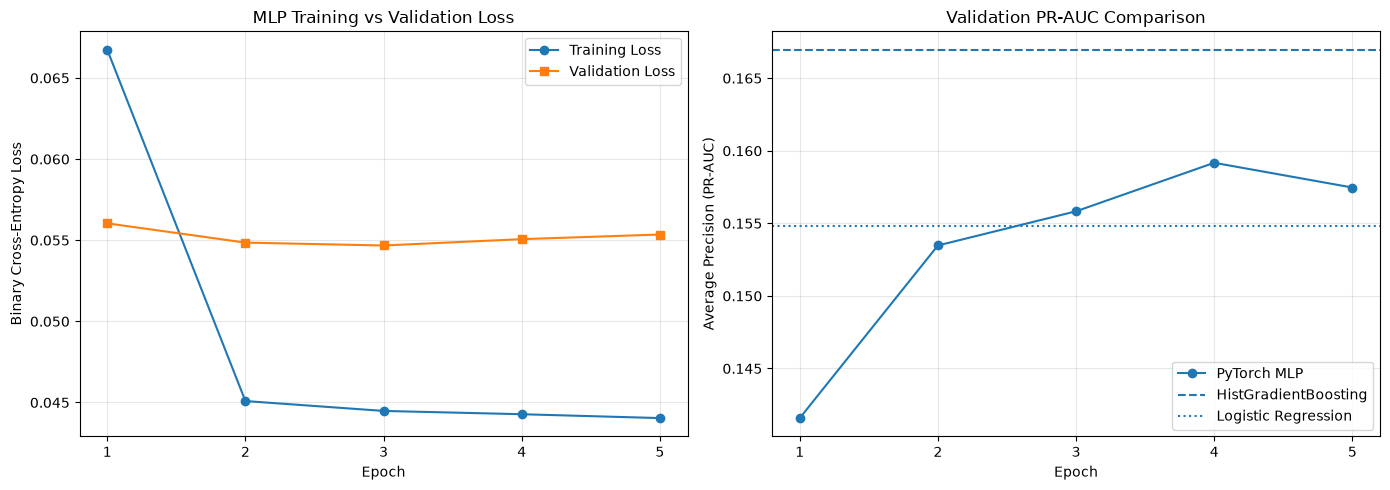

Completed epochs: 5
Final epoch: 5
Final validation PR-AUC: 0.157469
Gap vs HistGradientBoosting: -0.009492

Learning curve visualization: PASS


In [18]:

# ============================================================
# Milestone 05 — Cell 18: Visualize Learning Curves
# ============================================================

import matplotlib.pyplot as plt

# Build learning history DataFrame
history_df = pd.DataFrame(mlp_history)

# Verify experiment history
assert len(history_df) == TOTAL_EPOCHS
assert history_df["epoch"].tolist() == [1, 2, 3, 4, 5]

# Create side-by-side learning curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ------------------------------------------------------------
# Chart A: Training vs Validation Loss
# ------------------------------------------------------------

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss",
)

axes[0].plot(
    history_df["epoch"],
    history_df["validation_loss"],
    marker="s",
    label="Validation Loss",
)

axes[0].set_title("MLP Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].set_xticks(history_df["epoch"])
axes[0].legend()
axes[0].grid(alpha=0.3)

# ------------------------------------------------------------
# Chart B: Validation PR-AUC vs Baselines
# ------------------------------------------------------------

axes[1].plot(
    history_df["epoch"],
    history_df["validation_pr_auc"],
    marker="o",
    label="PyTorch MLP",
)

axes[1].axhline(
    HGB_PR_AUC,
    linestyle="--",
    label="HistGradientBoosting",
)

axes[1].axhline(
    LR_PR_AUC,
    linestyle=":",
    label="Logistic Regression",
)

axes[1].set_title("Validation PR-AUC Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Average Precision (PR-AUC)")
axes[1].set_xticks(history_df["epoch"])
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Summarize fixed-budget outcome
final_epoch = history_df.iloc[-1]

print("Completed epochs:", len(history_df))
print("Final epoch:", int(final_epoch["epoch"]))

print(
    "Final validation PR-AUC:",
    round(float(final_epoch["validation_pr_auc"]), 6),
)

print(
    "Gap vs HistGradientBoosting:",
    round(
        float(final_epoch["validation_pr_auc"]) - HGB_PR_AUC,
        6,
    ),
)

print("\nLearning curve visualization: PASS")


## 1. Instructor's Analysis — What the Charts Tell Us
Chart A — Training vs. Validation Loss
Training loss consistently decreased from 0.066739 to 0.044040. Validation loss reached its minimum at Epoch 3 before gradually increasing.
Interpretation: The model is learning, but the divergence between training and validation loss suggests possible early overfitting. This is a warning sign, not definitive proof.

Chart B — Validation PR-AUC
PR-AUC improved through Epoch 4, reaching 0.159173, before declining slightly to 0.157469 at Epoch 5.
Interpretation: Additional training improved fraud ranking compared with Epoch 1, but improvement was not continuous. The final fixed-budget model remained below HistGradientBoosting.

## 2. Milestone 05 Performance Summary
- Initial MLP PR-AUC
0.1416
Epoch 1

- Final MLP PR-AUC
0.1575
Epoch 5

- HGB Benchmark
0.1670
Milestone 04

Our initial MLP improved approximately 11.2% in PR-AUC after five epochs compared with its first epoch.
The final model outperformed Logistic Regression on validation PR-AUC, although HistGradientBoosting remains the strongest model we've evaluated.
We will retain the Epoch 5 model as our fixed-budget result. We will not retroactively select Epoch 4 merely because its validation PR-AUC was higher.

### Save Our Trained PyTorch Model

In [19]:

# ============================================================
# Milestone 05 — Cell 19: Save Trained MLP Weights
# ============================================================

# Confirm the fixed-budget experiment is complete
assert len(mlp_history) == TOTAL_EPOCHS == 5

assert final_optimizer_steps == (
    TOTAL_EPOCHS * len(train_loader)
)


# Separate directory for fresh-kernel reproduction
REPRO_RUN_ID = "milestone_05_repro_01"

MODEL_DIR = PROJECT_ROOT / "models" / REPRO_RUN_ID
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_CHECKPOINT_PATH = (
    MODEL_DIR / "milestone_05_mlp_epoch5.pt"
)

# Prevent accidentally overwriting an existing checkpoint
if MODEL_CHECKPOINT_PATH.exists():
    raise FileExistsError(
        f"Checkpoint already exists: {MODEL_CHECKPOINT_PATH}. "
        "Use a new REPRO_RUN_ID instead of overwriting it."
    )

# Save model parameters only
torch.save(
    mlp_model.state_dict(),
    MODEL_CHECKPOINT_PATH,
)

# Verify checkpoint exists
assert MODEL_CHECKPOINT_PATH.is_file()

# Reload safely for verification
loaded_state = torch.load(
    MODEL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True,
)

# Verify saved weights match our trained model
original_state = mlp_model.state_dict()

assert original_state.keys() == loaded_state.keys()

weights_match = all(
    torch.equal(
        original_state[name].cpu(),
        loaded_state[name],
    )
    for name in original_state
)

assert weights_match

print("Checkpoint:", MODEL_CHECKPOINT_PATH.name)
print("File exists:", MODEL_CHECKPOINT_PATH.is_file())

print(
    "File size (KB):",
    round(MODEL_CHECKPOINT_PATH.stat().st_size / 1024, 2),
)

print("Training epochs:", TOTAL_EPOCHS)
print("Saved parameter tensors:", len(loaded_state))
print("Saved weights match original:", weights_match)

print("\nModel checkpoint verification: PASS")


Checkpoint: milestone_05_mlp_epoch5.pt
File exists: True
File size (KB): 25.58
Training epochs: 5
Saved parameter tensors: 6
Saved weights match original: True

Model checkpoint verification: PASS


### Save the Fitted Preprocessing Pipeline

In [20]:

# ============================================================
# Milestone 05 — Cell 20: Save Fitted Preprocessor
# ============================================================

import joblib

# Define preprocessing artifact path
PREPROCESSOR_ARTIFACT_PATH = (
    MODEL_DIR / "milestone_05_preprocessor.joblib"
)

# Prevent overwriting an existing preprocessing artifact
if PREPROCESSOR_ARTIFACT_PATH.exists():
    raise FileExistsError(
        "Preprocessor artifact already exists: "
        f"{PREPROCESSOR_ARTIFACT_PATH}. "
        "Use a new REPRO_RUN_ID instead of overwriting it."
    )

# Save the ALREADY-FITTED preprocessing pipeline
# Do not fit or refit the preprocessor.
joblib.dump(
    preprocessor,
    PREPROCESSOR_ARTIFACT_PATH,
)

# Verify artifact exists
assert PREPROCESSOR_ARTIFACT_PATH.is_file()

# Reload the trusted, locally created artifact
loaded_preprocessor = joblib.load(
    PREPROCESSOR_ARTIFACT_PATH
)

# Verify feature names match the original pipeline
original_feature_names = (
    preprocessor.get_feature_names_out()
)

loaded_feature_names = (
    loaded_preprocessor.get_feature_names_out()
)

assert np.array_equal(
    original_feature_names,
    loaded_feature_names,
)

# Verify training transformations are reproducible
sample_train = train_features.iloc[:10]

reloaded_train = np.asarray(
    loaded_preprocessor.transform(sample_train),
    dtype=np.float32,
)

np.testing.assert_allclose(
    reloaded_train,
    X_train[:10],
    rtol=1e-6,
    atol=1e-6,
)

# Verify validation transformations are reproducible
sample_validation = validation_features.iloc[:10]

reloaded_validation = np.asarray(
    loaded_preprocessor.transform(sample_validation),
    dtype=np.float32,
)

np.testing.assert_allclose(
    reloaded_validation,
    X_validation[:10],
    rtol=1e-6,
    atol=1e-6,
)

print("Artifact:", PREPROCESSOR_ARTIFACT_PATH.name)
print("File exists:", PREPROCESSOR_ARTIFACT_PATH.is_file())

print(
    "File size (KB):",
    round(
        PREPROCESSOR_ARTIFACT_PATH.stat().st_size / 1024,
        2,
    ),
)

print("Transformed features:", len(loaded_feature_names))

print("\nFeature names match: PASS")
print("Training transform matches: PASS")
print("Validation transform matches: PASS")

print("\nPreprocessor artifact verification: PASS")


Artifact: milestone_05_preprocessor.joblib
File exists: True
File size (KB): 6.41
Transformed features: 55

Feature names match: PASS
Training transform matches: PASS
Validation transform matches: PASS

Preprocessor artifact verification: PASS


### Save the Five-Epoch Experiment History

In [ ]:

# ============================================================
# Milestone 05 — Cell 21: Save Experiment History
# ============================================================


# Store reproduction artifacts separately
ARTIFACT_DIR = (
    PROJECT_ROOT / "artifacts" / REPRO_RUN_ID
)

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
# Save this run's history in its isolated reproduction directory
HISTORY_PATH = ARTIFACT_DIR / "milestone_05_mlp_history.csv"

# Prevent overwriting existing experiment history
if HISTORY_PATH.exists():
    raise FileExistsError(
        f"Experiment history already exists: {HISTORY_PATH}. "
        "Use a new REPRO_RUN_ID instead of overwriting it."
    )

# Convert recorded experiments to a DataFrame
history_export = pd.DataFrame(mlp_history)

# Define expected schema
expected_columns = [
    "epoch",
    "train_loss",
    "validation_loss",
    "validation_pr_auc",
    "validation_roc_auc",
]

# Verify history before saving
assert history_export.columns.tolist() == expected_columns
assert history_export["epoch"].tolist() == [1, 2, 3, 4, 5]

assert np.isfinite(
    history_export[expected_columns[1:]].to_numpy()
).all()

# Save full numerical precision
history_export.to_csv(
    HISTORY_PATH,
    index=False,
    float_format="%.17g",
)

# Reload saved artifact
reloaded_history = pd.read_csv(HISTORY_PATH)

# Verify saved results reproduce original history
pd.testing.assert_frame_equal(
    history_export,
    reloaded_history,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12,
)


# Verify the fixed-budget final result dynamically
final_pr_auc = float(
    reloaded_history.iloc[-1]["validation_pr_auc"]
)

expected_final_pr_auc = float(
    mlp_history[-1]["validation_pr_auc"]
)

# PR-AUC must be finite and within its valid range
assert np.isfinite(final_pr_auc)
assert 0.0 <= final_pr_auc <= 1.0

# Saved result must match the current experiment
np.testing.assert_allclose(
    final_pr_auc,
    expected_final_pr_auc,
    rtol=1e-12,
    atol=1e-12,
)

print("Artifact:", HISTORY_PATH.name)
print("File exists:", HISTORY_PATH.is_file())
print("Recorded epochs:", len(reloaded_history))
print("Recorded metrics:", len(expected_columns) - 1)

print("\nSAVED EXPERIMENT HISTORY")
print(reloaded_history.round(6).to_string(index=False))

print("\nHistory reload matches original: PASS")
print("Experiment history artifact: PASS")


NameError: name 'HISTORY_PATH' is not defined

### Save Model Metadata and Reproducibility Configuration

In [ ]:

# ============================================================
# Milestone 05 — Cell 22: Model Metadata and Reproducibility
# ============================================================

import json
import sklearn

# Define metadata artifact
METADATA_PATH = (
    ARTIFACT_DIR / "milestone_05_mlp_metadata.json"
)

# Prevent overwriting existing experiment metadata
if METADATA_PATH.exists():
    raise FileExistsError(
        f"Model metadata already exists: {METADATA_PATH}. "
        "Use a new REPRO_RUN_ID instead of overwriting it."
    )

# Verify required artifacts
assert MODEL_CHECKPOINT_PATH.is_file()
assert PREPROCESSOR_ARTIFACT_PATH.is_file()
assert HISTORY_PATH.is_file()

# Verify experiment completion
assert len(mlp_history) == TOTAL_EPOCHS == 5

# Build reproducibility metadata
model_metadata = {
    "milestone": "05",
    "model_name": "PyTorch_FraudMLP",
    "model_version": "1.0",

    "architecture": {
        "input_features": int(X_train.shape[1]),
        "hidden_layers": [64, 32],
        "activation": "ReLU",
        "dropout": 0.10,
        "output_units": 1,
        "output_type": "raw_logit",
        "trainable_parameters": int(trainable_parameters),
    },

    "training": {
        "epochs": TOTAL_EPOCHS,
        "batch_size": BATCH_SIZE,
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "loss_function": "BCEWithLogitsLoss",
        "class_weighting": False,
        "random_seed": SEED,
        "device": str(DEVICE),
    },

    "data": {
        "dataset": "Base.csv",
        "target": TARGET,
        "temporal_field": MONTH,
        "train_months": split_config["train"]["months"],
        "validation_months": split_config["validation"]["months"],
        "test_status": "SEALED",
        "train_records": len(train_dataset),
        "validation_records": len(validation_dataset),
        "processed_feature_names": [
            str(name) for name in processed_feature_names
        ],
    },

    "validation_results": {
        "final_epoch": TOTAL_EPOCHS,
        "pr_auc": float(
            history_export.iloc[-1]["validation_pr_auc"]
        ),
        "roc_auc": float(
            history_export.iloc[-1]["validation_roc_auc"]
        ),
        "validation_loss": float(
            history_export.iloc[-1]["validation_loss"]
        ),
        "histgradientboosting_pr_auc": HGB_PR_AUC,
    },

    "artifacts": {
        "model_checkpoint": MODEL_CHECKPOINT_PATH.name,
        "preprocessor": PREPROCESSOR_ARTIFACT_PATH.name,
        "training_history": HISTORY_PATH.name,
    },

    "software": {
        "python": sys.version.split()[0],
        "pytorch": str(torch.__version__),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
    },
}

# Save metadata
with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(
        model_metadata,
        file,
        indent=2,
    )

# Reload and verify
with open(METADATA_PATH, "r", encoding="utf-8") as file:
    loaded_metadata = json.load(file)

assert loaded_metadata == model_metadata

assert loaded_metadata["architecture"]["input_features"] == 55
assert loaded_metadata["architecture"]["trainable_parameters"] == 5697
assert loaded_metadata["training"]["epochs"] == 5
assert loaded_metadata["data"]["test_status"] == "SEALED"

assert len(
    loaded_metadata["data"]["processed_feature_names"]
) == 55

# Display verification
print("Metadata artifact:", METADATA_PATH.name)
print("File exists:", METADATA_PATH.is_file())

print("\nModel:", loaded_metadata["model_name"])
print("Version:", loaded_metadata["model_version"])

print(
    "Input features:",
    loaded_metadata["architecture"]["input_features"],
)

print(
    "Hidden layers:",
    loaded_metadata["architecture"]["hidden_layers"],
)

print(
    "Training epochs:",
    loaded_metadata["training"]["epochs"],
)

print(
    "Final PR-AUC:",
    round(
        loaded_metadata["validation_results"]["pr_auc"],
        6,
    ),
)

print(
    "Test status:",
    loaded_metadata["data"]["test_status"],
)

print("\nMetadata reload matches original: PASS")
print("Model reproducibility metadata: PASS")


Metadata artifact: milestone_05_mlp_metadata.json
File exists: True

Model: PyTorch_FraudMLP
Version: 1.0
Input features: 55
Hidden layers: [64, 32]
Training epochs: 5
Final PR-AUC: 0.157469
Test status: SEALED

Metadata reload matches original: PASS
Model reproducibility metadata: PASS


### Reconstruct the Trained MLP and Verify Predictions

In [ ]:

# ============================================================
# Milestone 05 — Cell 23: Model Reload and Inference Test
# ============================================================

# Reload metadata from disk
with open(METADATA_PATH, "r", encoding="utf-8") as file:
    saved_metadata = json.load(file)

architecture = saved_metadata["architecture"]

# Confirm compatibility with our current FraudMLP definition
assert architecture["hidden_layers"] == [64, 32]
assert architecture["output_units"] == 1
assert architecture["output_type"] == "raw_logit"

# Reconstruct a NEW model instance
reloaded_mlp = FraudMLP(
    input_dim=architecture["input_features"],
    dropout_rate=architecture["dropout"],
).to(DEVICE)

# Load trained parameters from disk
saved_weights = torch.load(
    MODEL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True,
)

reloaded_mlp.load_state_dict(
    saved_weights,
    strict=True,
)

# Reload trusted fitted preprocessor
reloaded_preprocessor = joblib.load(
    PREPROCESSOR_ARTIFACT_PATH
)

# Use a small VALIDATION sample only
sample_size = 128
sample_raw_features = validation_features.iloc[:sample_size]

# Apply saved preprocessing without refitting
sample_processed = np.asarray(
    reloaded_preprocessor.transform(sample_raw_features),
    dtype=np.float32,
)

# Verify feature transformation consistency
np.testing.assert_allclose(
    sample_processed,
    X_validation[:sample_size],
    rtol=1e-6,
    atol=1e-6,
)

# Prepare tensors
original_inputs = torch.from_numpy(
    X_validation[:sample_size]
).to(DEVICE)

reloaded_inputs = torch.from_numpy(
    sample_processed
).to(DEVICE)

# Preserve original model mode
original_training_mode = mlp_model.training

# Evaluation mode disables dropout
mlp_model.eval()
reloaded_mlp.eval()

with torch.inference_mode():

    # Original model predictions
    original_logits = mlp_model(original_inputs)
    original_probabilities = torch.sigmoid(
        original_logits
    )

    # Reloaded model predictions
    reloaded_logits = reloaded_mlp(reloaded_inputs)
    reloaded_probabilities = torch.sigmoid(
        reloaded_logits
    )

# Verify predictions are identical
torch.testing.assert_close(
    original_logits,
    reloaded_logits,
    rtol=0,
    atol=0,
)

torch.testing.assert_close(
    original_probabilities,
    reloaded_probabilities,
    rtol=0,
    atol=0,
)

# Verify prediction dimensions and validity
assert reloaded_probabilities.shape == (sample_size,)
assert torch.isfinite(reloaded_probabilities).all().item()

# Restore original model mode
mlp_model.train(original_training_mode)

print("Model checkpoint loaded: PASS")
print("Fitted preprocessor loaded: PASS")

print("\nValidation sample size:", sample_size)
print("Input features:", sample_processed.shape[1])
print("Prediction shape:", tuple(reloaded_probabilities.shape))

print("\nPreprocessing consistency: PASS")
print("Logit comparison: PASS")
print("Probability comparison: PASS")

print("\nSaved-model inference verification: PASS")


Model checkpoint loaded: PASS
Fitted preprocessor loaded: PASS

Validation sample size: 128
Input features: 55
Prediction shape: (128,)

Preprocessing consistency: PASS
Logit comparison: PASS
Probability comparison: PASS

Saved-model inference verification: PASS


### Create a Reusable PyTorch Model Module

In [ ]:

# ============================================================
# Bank Account Fraud Detection
# Reusable PyTorch MLP Architecture
# ============================================================

from torch import nn


class FraudMLP(nn.Module):
    """
    Multilayer Perceptron for binary fraud classification.

    Architecture:
        Input -> 64 -> ReLU -> Dropout
              -> 32 -> ReLU -> Dropout
              -> 1 raw logit

    The model returns raw logits for use with
    BCEWithLogitsLoss during training.
    """

    def __init__(
        self,
        input_dim=55,
        dropout_rate=0.10,
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),

            nn.Linear(32, 1),
        )

    def forward(self, x):
        """Return one raw logit per observation."""
        return self.network(x).squeeze(-1)